In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

import matplotlib as mpl

from scipy import interpolate
import scipy.optimize

from copy import deepcopy
import time
from tqdm import tqdm

from ngsolve import *
from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

# my functions
from helper_functions import *
from dipole_poisson_solver import dipole_poisson_solver

In [2]:
### unit-system: Angstrom = 1, eV = 1, e_charge = 1

### choices, see lammps metal system: https://docs.lammps.org/units.html

Angstrom = 1
eV = 1
e_charge = 1
Volt = 1

### independent

finestructure_constant = 0.0072973525643 # Finestructure constant, independent of unit-system   , https://en.wikipedia.org/wiki/Fine-structure_constant

### derived

hbar = 6.582119569 * pow(10.0, -4.0) ## eV * pico seconds, 1 pico second = 10^(-12) seconds

### units of time are in pico seconds, this implies units of velocity are in Angstrom / picoseconds

c_speed_of_light = 2.99792458 * pow(10.0, 6.0) ## Angstrom/pico seconds

pico_second = 1

nm = 10 ## 1nm = 10 Angstrom


hbar_times_c = 1973  # eV * Angstrom  # https://en.wikipedia.org/wiki/Planck_constant#Reduced_Planck_constant
h_times_c = 2.0 * np.pi * hbar_times_c

epsilon_0 = (e_charge * e_charge) / (2.0 * finestructure_constant * h_times_c)    # https://en.wikipedia.org/wiki/Vacuum_permittivity
mu_0 = 1.0 / (c_speed_of_light * epsilon_0)    # https://en.wikipedia.org/wiki/Vacuum_permeability
mu_0 /= c_speed_of_light ### don't divide by c^2 immediately

######################
######################
######################


### constants
a_lattice = 2.46

grapheneheight = 3.35 # Angstrom

blg_grapheneheight = grapheneheight ### see Jung & MacDonald PRB 89, 035405 (2014) #2.0 * grapheneheight

bilayer_graphene_area, bilayer_graphene_volume = blg_area_vol(a_lattice, blg_grapheneheight, Angstrom)
print(blg_grapheneheight)

3.35


In [17]:
vac_box_width = 200 * nm
height_bottom = 15 * nm 
height_top = height_bottom
vac_box_width = height_bottom * 10 # box width is 10 times hbn thickness
dipole_moment_debye = 40

sphere_radius = 3 # 3
benzen_a = 1.4 # Angstrom
benzen_diameter = 2 * benzen_a
dipole_position = 0.02 * vac_box_width # basically 0


dipole_d = 3 * benzen_diameter 

#back_gate = 0.004081632653061218 # sus
back_gate = -0.01
max_h = vac_box_width/30 #vac_box_width/10

fem_n = 300
epsilon_z = 1e-4
print('simulation dimensions in Angstrom: ')
print('hBb thickness: ', height_bottom)
print('blg thichness: ', blg_grapheneheight)
print('box width: ', vac_box_width)
print('dipole d: ', dipole_d)
print('dipole height over hBn: ', dipole_position)
print('dipole sphere radius: ', sphere_radius)

simulation dimensions in Angstrom: 
hBb thickness:  150
blg thichness:  3.35
box width:  1500
dipole d:  8.399999999999999
dipole height over hBn:  30.0
dipole sphere radius:  3


In [18]:
# eps tensor
inplane_hBn_bulk = 4.98 ### see https://www.nature.com/articles/s41699-018-0050-x 
outofplane_hBn_bulk = 3.03

inplane_graphene = 1.8 ### https://pubs.acs.org/doi/10.1021/nl303611v
outofplane_graphene = 3

inplane_MoS2 = 15.4 ### https://www.nature.com/articles/s41699-018-0050-x
outofplane_MoS2 = 6.1

In [5]:
dummy_idos_shape = np.zeros(2, np.int64)


dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.5meV_U_range_0_200_meV_increment_0.5meV_VSC"

#dos_folder = "new_ps_helper_functions/JungMacDonald_energy_range_m200meV_200meV_increment_0.25meV_U_range_0_200_meV_increment_0.25meV_VSC"




### read arrays

idos = np.load(dos_folder+"/idos_blg.npy")
    
band_gaps = np.load(dos_folder+"/band_gap.npy")

displacement_field_intervals = np.load(dos_folder+"/displacementfield_intervalls.npy")

energy_interval = np.load(dos_folder+"/energy_intervall.npy")

### shapes


#dummy_idos_shape = read_idos.shape

In [6]:
correct_prefactor = 1.0 / (bilayer_graphene_volume) ### this dos is already in units of 1/Energy, convert to density/Energy

idos = -idos * correct_prefactor


en_min = energy_interval[0] ## -0.2 eV
en_max = energy_interval[-1]  ## 0.2 eV

pot_min = displacement_field_intervals[0]  ## 0 eV
pot_max = displacement_field_intervals[-1] ## 0.2 eV


en_steps = idos.shape[1] 

e_incr = (en_max - en_min) / (en_steps - 1)

pot_steps = idos.shape[0] 

pot_incr = (pot_max - pot_min) / (pot_steps - 1)

en_intervall = np.linspace(en_min, en_max, en_steps)

en_incr = (en_max - en_min) / (en_steps - 1)

pot_intervall = np.linspace(pot_min, pot_max, pot_steps)

en_mesh, pot_mesh = np.meshgrid(en_intervall, pot_intervall)  # 2D grid for interpolation

begin_barycentricscipy_interpolation_time = time.time()

idos_interpolated = scipy.interpolate.LinearNDInterpolator(np.array([np.ravel(pot_mesh), np.ravel(en_mesh)]).T,
                                                           idos.reshape(pot_steps*en_steps))

end_barycentricscipy_interpolation_time = time.time()


print("interpolation took ", end_barycentricscipy_interpolation_time - begin_barycentricscipy_interpolation_time, " seconds")

interpolation took  2.8598039150238037  seconds


In [19]:
test_solver = dipole_poisson_solver(dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_graphene, outofplane_graphene, epsilon_0)
test_solver.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_h)
test_solver.solve_without_BLG(back_gate)
test_solver.solve(fem_n, epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, use_abs=True, starting_alpha=0.01)

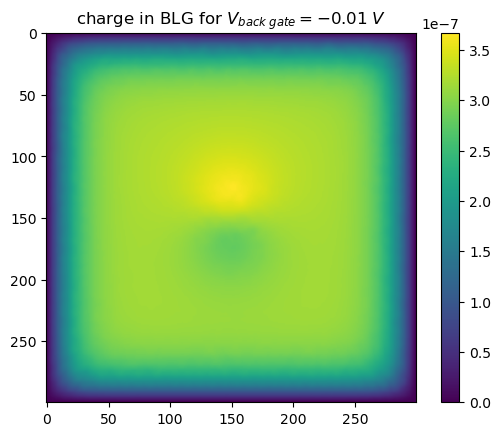

In [20]:
plt.imshow(test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n)))
plt.title(f'charge in BLG for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

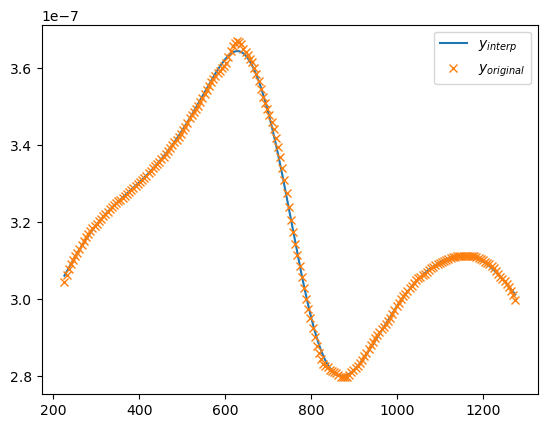

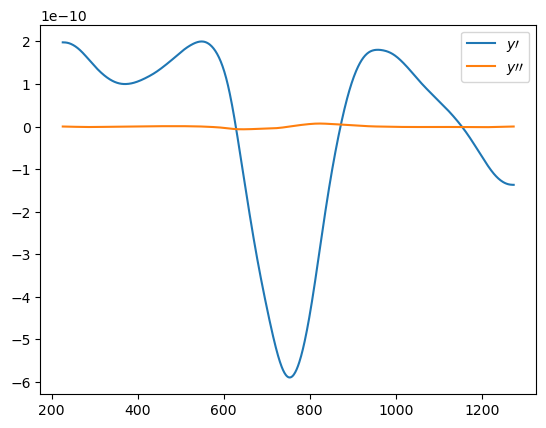

503
105
135


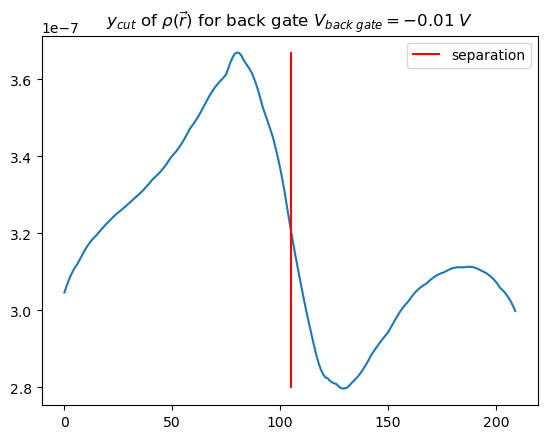

In [21]:
### induced dipole moment
# charge array
induced_charge = test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n))
middle_index = math.floor(induced_charge.shape[0]/2)
y_cut = induced_charge[:,middle_index]


# cut boundaries; finite size effects; 10% is removed
cut_percentage = 0.1
cut_index = int(cut_percentage/2 * induced_charge.shape[0])
induced_charge = induced_charge[cut_index:fem_n - cut_index, cut_index:fem_n - cut_index]
#y_cut = y_cut[cut_index:fem_n - cut_index]

# find separation
larger_cut_percentage = 0.3
larger_cut_index = int(larger_cut_percentage/2 * fem_n)
y_cut = y_cut[larger_cut_index:fem_n - larger_cut_index]

# x values
dx = vac_box_width/(fem_n - 1)
x_max = (fem_n - 1) * dx
x = np.linspace(0, x_max, fem_n)
#print(x[0])
#print(x[-1])

x = x[larger_cut_index:fem_n - larger_cut_index]


spline = interpolate.make_smoothing_spline(x, y_cut, lam=100000)
x_new = np.linspace(x[0], x[-1], 1000)

y_interp = spline(x_new)
y_prime = spline(x_new, nu=1)
y_double_prime = spline(x_new, nu=2)
plt.plot(x_new, y_interp, label='$y_{interp}$')
plt.plot(x, y_cut, 'x', label='$y_{original}$')
#plt.plot(x_new, y_prime, label='$y\\prime$')
#plt.plot(x_new, y_double_prime, label='$y\\prime \\prime$')
#plt.xlim((120, 130))
plt.legend()
plt.show()

plt.plot(x_new, y_prime, label='$y\\prime$')
plt.plot(x_new, y_double_prime, label='$y\\prime \\prime$')
plt.legend()
plt.show()


max_index = np.argmax(y_double_prime)
min_index = np.argmin(y_double_prime)

if max_index < min_index:
    sep_index = max_index + np.argmin(abs(y_double_prime[max_index:min_index]))
elif min_index < max_index:
    sep_index = min_index + np.argmin(abs(y_double_prime[min_index:max_index]))
print(sep_index)
#print(x_new[np.argmin(y_prime)])
#print(x_new[sep_index])
# bring sep_index back to original fem_n
sep_index = np.argmin(abs(x - x_new[sep_index]))
print(sep_index)
sep_index_final = larger_cut_index - cut_index + sep_index
print(sep_index_final)

# split charge array
top_charge = induced_charge[:sep_index_final, :]
bot_charge = induced_charge[sep_index_final:, :]


plt.plot(y_cut)
plt.vlines(sep_index, np.min(y_cut), np.max(y_cut), color='r', label='separation')
#plt.hlines(mean, 0, len(y_cut), color='g', label='mean')
plt.title(f'$y_{{cut}}$ of $\\rho(\\vec{{r}})$ for back gate $V_{{back\\;gate}}={back_gate} \\; V$')
plt.legend()

In [37]:
### find centers of charges

dx = vac_box_width/(fem_n - 1)
x_max = (fem_n - 1) * dx
x = np.linspace(0, x_max, fem_n)
y = np.linspace(0, x_max, fem_n)

# cut x and y; ignore boundary effects
x = x[cut_index:fem_n - cut_index]
y = y[cut_index:fem_n - cut_index]

# meshgrid
x_top = x[:sep_index_final]
x_bot = x[sep_index_final:]
X_top, Y_top = np.meshgrid(x_top, y, indexing='ij')
X_bot, Y_bot = np.meshgrid(x_bot, y, indexing='ij')

# top
shape_top = top_charge.shape
p_top_x = np.trapezoid(np.trapezoid(abs(top_charge) * X_top, dx=dx, axis=0), dx=dx, axis=0)
p_top_y = np.trapezoid(np.trapezoid(abs(top_charge) * Y_top, dx=dx, axis=0), dx=dx, axis=0)

Q_top = np.trapezoid(np.trapezoid(abs(top_charge), dx=dx, axis=0), dx=dx, axis=0) * test_solver.blg_height

p_top = (np.array([p_top_x, p_top_y]) * test_solver.blg_height)
center_of_charge_top = p_top/Q_top

# bottom
p_bot_x = np.trapezoid(np.trapezoid(abs(bot_charge) * X_bot, dx=dx, axis=0), dx=dx, axis=0)
p_bot_y = np.trapezoid(np.trapezoid(abs(bot_charge) * Y_bot, dx=dx, axis=0), dx=dx, axis=0)

Q_bot = np.trapezoid(np.trapezoid(abs(bot_charge), dx=dx, axis=0), dx=dx, axis=0) * test_solver.blg_height

p_bot = (np.array([p_bot_x, p_bot_y]) * test_solver.blg_height)
center_of_charge_bot = p_bot/Q_bot

# dipole moment
print(Q_top)
print(Q_bot)
print(Q_bot + Q_top)
print(test_solver.total_charge)

p = p_bot + p_top
#print(p)
#print(np.linalg.norm(p)/(vac_box_width * vac_box_width))
print(center_of_charge_top)

1.6727443718699795
1.6487280159623128
3.3214723878322925
3.6601728398440057
[561.06099448 999.52939088]


In [38]:
# distance between centers of charges
d_vec = center_of_charge_top - center_of_charge_bot
print(d_vec)
print(test_solver.d_vec)
print(np.linalg.norm(d_vec))
print(test_solver.separation)

[-8.81752832e+02 -2.76396508e-01]
[-8.81899697e+02 -2.63286703e-01]
881.752875160035
881.8997367192801


In [39]:
print(center_of_charge_top)
print(center_of_charge_bot)
print(test_solver.center_of_charge_top)
print(test_solver.center_of_charge_bot)
print(Q_top)
print(Q_bot)
print(test_solver.Q_top)
print(test_solver.Q_bot)
print(test_solver.sep_index)
print(sep_index_final)

[561.06099448 999.52939088]
[1442.81382632  999.80578739]
[567.70296125 999.53792289]
[1449.60265866  999.8012096 ]
1.6727443718699795
1.6487280159623128
1.6982480078954831
1.6232649105689294
137
135


Text(0, 0.5, '$x$')

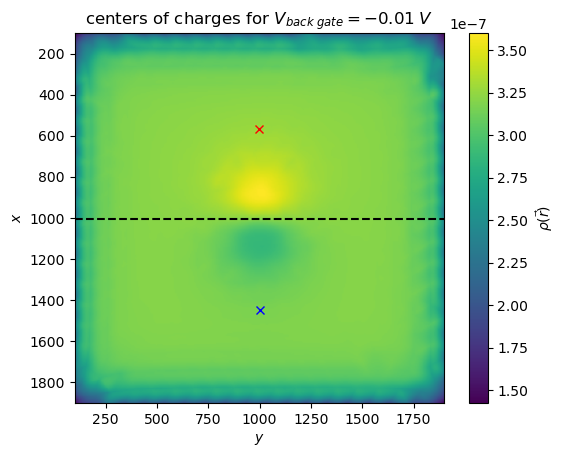

In [40]:
plt.imshow(induced_charge, extent=[x.min(), x.max(), y.max(), y.min()])
plt.plot(test_solver.center_of_charge_top[1], test_solver.center_of_charge_top[0], 'rx')
plt.plot(test_solver.center_of_charge_bot[1], test_solver.center_of_charge_bot[0], 'bx')
#plt.plot(center_of_charge_top[1], center_of_charge_top[0], 'rx')
#plt.plot(center_of_charge_bot[1], center_of_charge_bot[0], 'bx')
plt.hlines(x[sep_index_final], x.min(), x.max(), color='black', linestyle='dashed')
plt.colorbar(label='$\\rho(\\vec{{r}})$')
plt.title(f'centers of charges for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.xlabel('$y$')
plt.ylabel('$x$')

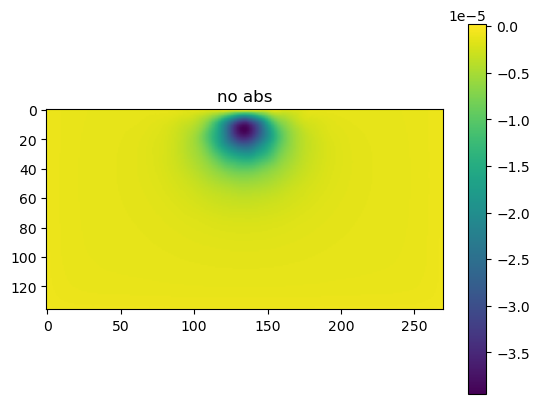

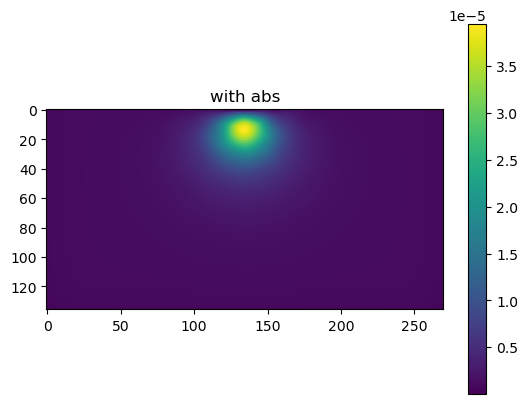

In [51]:
plt.imshow(bot_charge)
plt.colorbar()
plt.title('no abs')
plt.show()

plt.imshow(abs(bot_charge))
plt.colorbar()
plt.title('with abs')
plt.show()

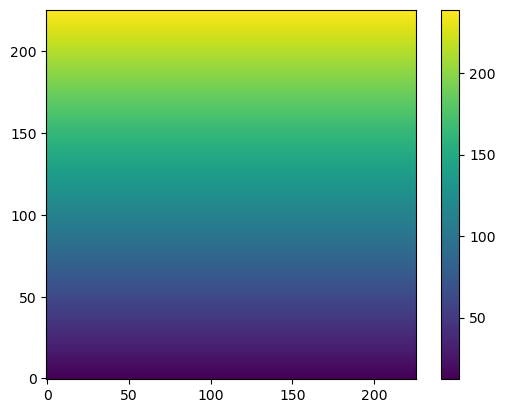

In [52]:
X_con = np.concatenate([X_top, X_bot])
plt.imshow(X, origin='lower')
plt.colorbar()

[[ 12.09657909  12.09657909  12.09657909 ...  12.09657909  12.09657909
   12.09657909]
 [ 13.10462734  13.10462734  13.10462734 ...  13.10462734  13.10462734
   13.10462734]
 [ 14.1126756   14.1126756   14.1126756  ...  14.1126756   14.1126756
   14.1126756 ]
 ...
 [236.89134046 236.89134046 236.89134046 ... 236.89134046 236.89134046
  236.89134046]
 [237.89938872 237.89938872 237.89938872 ... 237.89938872 237.89938872
  237.89938872]
 [238.90743698 238.90743698 238.90743698 ... 238.90743698 238.90743698
  238.90743698]]


In [88]:
print(test_solver.dipole_moment)
print(test_solver.total_charge)

8.3277708
2.4601692094066854


In [ ]:
# potential straight up in z-direction
diagonal_vec = np.array([vac_box_width, vac_box_width, height_bottom + blg_grapheneheight + height_top + vac_box_width])
diagonal = np.linalg.norm(diagonal_vec)
diagonal_unit_vec = diagonal_vec/diagonal

starting_point = np.array([0.45 * vac_box_width, 0.45 * vac_box_width, 0])

#rs = np.linspace(0, diagonal, 400)
rs = np.linspace(0, blg_grapheneheight + vac_box_width + height_bottom + height_top, 400)

gfu_values = []

for r in rs:
    #print(r)
    p = starting_point + r * np.array([0,0,1]) #diagonal_unit_vec
    gfu_values.append(test_solver.gfu(test_solver.mesh_dipole(*p)))

In [ ]:
plt.plot(rs, gfu_values)
plt.title("potential in z-direction next to dipole")
plt.xlabel('$z$')
plt.ylabel('$\\phi(z)$')

In [ ]:
# potential on main diagonal (in BLG)
gfu_values_diag =[]

diagonal_vec = np.array([vac_box_width, vac_box_width, blg_grapheneheight])
diagonal = np.linalg.norm(diagonal_vec)
diagonal_unit_vec = diagonal_vec/diagonal

starting_point = np.array([0.0, 0.0, height_bottom])

rs_diag = np.linspace(0, diagonal, 400)

gfu_values = []

for r in rs_diag:
    #print(r)
    p = starting_point + r * diagonal_unit_vec
    gfu_values_diag.append(test_solver.gfu(test_solver.mesh_dipole(*p)))

In [ ]:
plt.plot(rs_diag, gfu_values_diag)
plt.title("potential on main diagonal in BLG")
plt.xlabel('$r$')
plt.ylabel('$\\phi$')

In [50]:
### dipole moment without splitting
X, Y = np.meshgrid(x, y, indexing='ij')

p_x = np.trapezoid(
    np.trapezoid(induced_charge * X, y, axis=1),
    x,
    axis=0
)

p_y = np.trapezoid(
    np.trapezoid(induced_charge * Y, y, axis=1),
    x,
    axis=0
)

p = np.array([p_x, p_y])
print(p)
print(np.linalg.norm(p) * test_solver.blg_height/(vac_box_width * vac_box_width))

[167.68611922 169.39016469]
0.01277566568946103


In [89]:
x = np.linspace(0, x_max, fem_n)
y = np.linspace(0, x_max, fem_n)

Q_ind = np.trapezoid(
    np.trapezoid(test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n)), y, axis=1),
    x,
    axis=0
)
print(Q_ind)

0.7342900711645773


In [15]:
V_increments = -1.0
number_increments = 5
max_hs = np.linspace(vac_box_width/5, vac_box_width/40, number_increments)
print(max_hs)

fem_ns = np.linspace(100, 1000, number_increments).round().astype(int)
print(fem_ns)

test_solver_increments = dipole_poisson_solver(dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_graphene, outofplane_graphene, epsilon_0)

[50.     39.0625 28.125  17.1875  6.25  ]
[ 100  325  550  775 1000]


In [ ]:

test_solver.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_h)
test_solver.solve_without_BLG(back_gate)
test_solver.solve(fem_n, epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, starting_alpha=0.01)

In [17]:
times = np.zeros((number_increments, number_increments))
its = np.zeros((number_increments, number_increments))

# i over max_hs and j over fem_ns
for i in range(number_increments):
    for j in range(number_increments):
        test_solver_increments.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_hs[i])
        test_solver_increments.solve_without_BLG(V_increments)
        test_solver_increments.solve(fem_ns[j], epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, starting_alpha=0.01)

        times[i, j] = test_solver_increments.solver_time
        its[i, j] = test_solver_increments.global_it[0]

# 0   rho_n-1 - rho_n (max):  0.0004033599750714218
# 0   |q_n-1 - q_n| :  78.7106689921979
# 1   rho_n-1 - rho_n (max):  0.000692456293255215
# 1   |q_n-1 - q_n| :  115.5674774302002
# 2   rho_n-1 - rho_n (max):  0.0008065655064726969
# 2   |q_n-1 - q_n| :  160.766589814781
# 3   rho_n-1 - rho_n (max):  0.0002789710610026627
# 3   |q_n-1 - q_n| :  51.0908069860417
# 4   rho_n-1 - rho_n (max):  0.0005452402355581436
# 4   |q_n-1 - q_n| :  88.1720458887123
# 5   rho_n-1 - rho_n (max):  0.0005299718755701044
# 5   |q_n-1 - q_n| :  101.43592278787474
# 6   rho_n-1 - rho_n (max):  0.00021674771125571631
# 6   |q_n-1 - q_n| :  35.35130337414307
# 7   rho_n-1 - rho_n (max):  0.00042627656574872603
# 7   |q_n-1 - q_n| :  65.73981942088051
# 8   rho_n-1 - rho_n (max):  0.00017116357756875175
# 8   |q_n-1 - q_n| :  18.65936535162775
# 9   rho_n-1 - rho_n (max):  0.00011699177441437913
# 9   |q_n-1 - q_n| :  2.7609577093085704
# 10   rho_n-1 - rho_n (max):  4.0931210727008236e-05
# 10   |q_n-1 -

In [18]:
print(its)
print(times)

[[33. 34. 34. 34. 34.]
 [30. 34. 33. 33. 33.]
 [33. 33. 33. 33. 33.]
 [31. 31. 31. 31. 31.]
 [30. 30. 30. 30. 30.]]
[[ 2.06406927  3.36961174  5.03303123  6.64997196  9.04510021]
 [ 2.0876472   4.66625428  4.77976537  8.61392879 13.82960987]
 [ 2.30927825  3.50225687  4.9332099   6.86748672 10.77442789]
 [ 4.3435061   3.91893268  5.18815708  7.26661539  9.5957222 ]
 [25.2487042  25.23701596 28.44606376 29.55219913 35.8329649 ]]


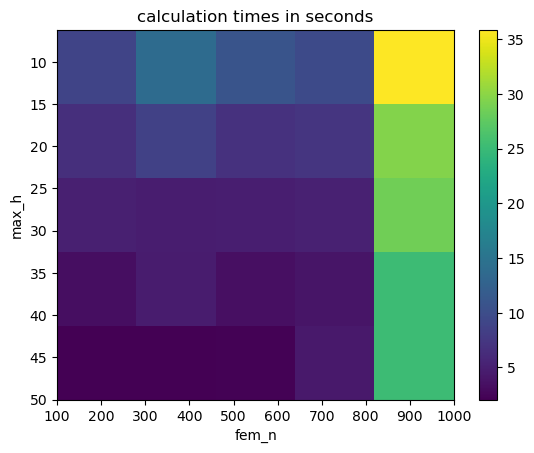

In [38]:
x = max_hs
y = fem_ns

X, Y = np.meshgrid(x,y, indexing='ij')
z = times

plt.imshow(
    z.T,
    origin='lower',
    extent=[y.min(), y.max(), x.max(), x.min()],
    aspect='auto'
)
plt.title('calculation times in seconds')
plt.xlabel('fem_n')
plt.ylabel('max_h')
plt.colorbar()
plt.show()

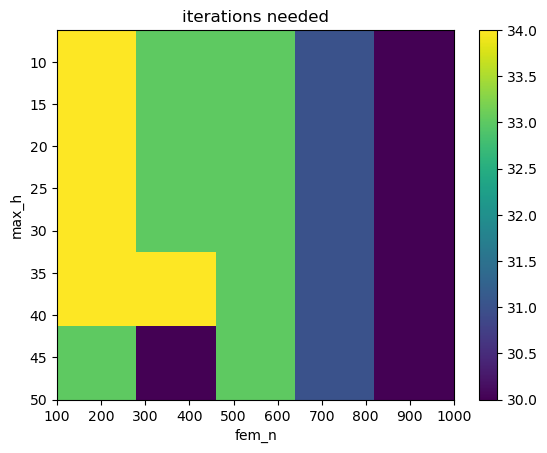

In [36]:
z = its

plt.imshow(
    z.T,
    origin='lower',
    extent=[y.min(), y.max(), x.max(), x.min()],
    aspect='auto'
)
plt.title('iterations needed')
plt.xlabel('fem_n')
plt.ylabel('max_h')
plt.colorbar()
plt.show()